# WIDS: Deauth, Disassociation and Reassociation Detection (AWID3)

Prototype Wi-Fi intrusion detector using a subset of AWID3. This notebook analyses three management-frame attacks: deauthentication, disassociation and (re)association.

## Deauthentication flood detection 

Goal: detect deauthentication floods from 1-second windows of 802.11 frames, using ML, then raise alerts on a replayed stream. The attack only appears in the later parts of the Deauth folder, so the parts are read one at a time (batching) and reduced to small per-second summaries.

In [1]:
import os, re
import numpy as np
import pandas as pd

root = '/kaggle/input/datasets/suumia/awid3-dataset/CSV'
folder = os.path.join(root, "1.Deauth")

def part_no(f):
    return int(re.findall(r"\d+", f)[-1])

deauth_parts = sorted(os.listdir(folder), key=part_no)
print(len(deauth_parts), "parts")

33 parts


## 1. Label check on one attack part

`Deauth_22` is loaded in full to check that the labels agree with the real frame type and subtype (type 0 = management, subtype 12 = deauthentication, subtype 10 = disassociation).

In [2]:
p = pd.read_csv(os.path.join(folder, "Deauth_22.csv"), low_memory=False)
print(pd.crosstab(p["Label"], [p["wlan.fc.type"], p["wlan.fc.subtype"]]))

wlan.fc.type     0                                         ...    1        \
wlan.fc.subtype 0  1   2   3    4   5    8   10  11    12  ...   8     9    
Label                                                      ...              
Deauth           0  0   0   0    0   0    0  14   0  5187  ...    0     0   
Normal           4  3  18  19  128  53  214  22  44     1  ...  462  5227   

wlan.fc.type                          2                    
wlan.fc.subtype     11    12    13   0   4      8  9   12  
Label                                                      
Deauth               0     0     0    0   0      0  0   0  
Normal           11560  6840  4487  112  35  14129  3  83  

[2 rows x 23 columns]


### Findings
- 5,187 of the 5,201 `Deauth` frames are type 0, subtype 12. The other 14 are subtype 10 (disassociation).
- Only 1 `Normal` frame is a deauth frame, so a deauth count should separate the classes very well. High scores are expected.
- 22 `Normal` frames are disassociation frames, so disassociation will be harder to detect.

## 2. Who sends the attack frames?

The attack frames are inspected for sender, receiver, BSSID and reason code, because this decides what the alert should log.

In [3]:
atk = p[p["Label"] == "Deauth"]
for c in ["wlan.sa", "wlan.da", "wlan.bssid", "wlan.fixed.reason_code"]:
    print(atk[c].value_counts().head(5), "\n")

wlan.sa
0c:9d:92:54:fe:34    2643
b4:ce:40:c8:33:81    1332
88:66:a5:55:a2:d4    1030
94:e9:79:82:c5:77     196
Name: count, dtype: int64 

wlan.da
0c:9d:92:54:fe:34    2558
b4:ce:40:c8:33:81    1497
88:66:a5:55:a2:d4     922
94:e9:79:82:c5:77     210
00:c0:ca:a8:26:3e      14
Name: count, dtype: int64 

wlan.bssid
0c:9d:92:54:fe:34    5201
Name: count, dtype: int64 

wlan.fixed.reason_code
7.0    4332
1.0     671
6.0     196
3.0       2
Name: count, dtype: int64 



### 🔍 Protocol-Level Analysis of Deauthentication Traffic (`Deauth_22.csv`)

To verify that the dataset labels correspond to genuine wireless attacks rather than anomalies, we inspected key IEEE 802.11 management frame fields (`wlan.sa`, `wlan.da`, `wlan.bssid`, and `wlan.fixed.reason_code`) for rows labeled as `Deauth`.

#### 1. Transmitter & Receiver Analysis (`wlan.sa`, `wlan.da`, `wlan.bssid`)
* **BSSID Consistency:** Every single attack frame points back to a single BSSID (`0c:9d:92:54:fe:34`), indicating that the attacker is impersonating or targeting a specific Access Point.
* **Source/Destination Pairs:** The primary sender (`wlan.sa`) and receiver (`wlan.da`) addresses match the flood pattern of an automated injection tool (e.g., `aireplay-ng`), where tear-down commands are blasted toward connected clients.

#### 2. Reason Code Breakdown (`wlan.fixed.reason_code`)
In the 802.11 standard, deauthentication frames carry reason codes explaining why the link is severed. The attack traffic is heavily dominated by programmatic codes:
* **Reason Code 7 (`4,332` instances):** *"Class 3 frame received from nonassociated station."* This is the hallmark signature of automated deauth flood tools, as frames are sent blindly to drop active client associations.
* **Reason Code 1 (`671` instances):** *"Unspecified reason."* A generic code utilized by custom spoofing scripts.
* **Reason Code 6 (`196` instances):** *"Class 2 frame received from nonauthenticated station."*

#### 💡 Takeaway for Feature Engineering
These fields confirm that features tracking **reason code frequencies**, **per-MAC packet velocity**, and **BSSID association anomalies** will serve as highly discriminative features for our Decision Tree and Random Forest classifiers.

## 3. Build 1-second windows in batches

Each part (about 50,000 frames) is read one at a time with only the needed columns. For each second, the frames are counted by kind. Seconds with no deauth frames are still included (their count is 0), because every second that has any frame gets a row. The deauth frames themselves are kept separately (they are few) so that alerts can report the BSSID and claimed senders.

A second can span two parts, so the per-part summaries are added together by second afterwards.

In [4]:
USE = ["frame.time_epoch", "wlan.fc.type", "wlan.fc.subtype",
       "wlan.sa", "wlan.da", "wlan.bssid", "Label"]

def read_part(path):
    c = pd.read_csv(path, usecols=USE, low_memory=False)
    c["sec"] = np.floor(c["frame.time_epoch"].astype(float)).astype("int64")
    is_mgmt   = c["wlan.fc.type"] == 0
    c["is_mgmt"]   = is_mgmt
    c["is_deauth"] = is_mgmt & (c["wlan.fc.subtype"] == 12)
    c["is_disas"]  = is_mgmt & (c["wlan.fc.subtype"] == 10)
    c["is_attack"] = c["Label"] != "Normal"

    win = c.groupby("sec").agg(
        n_frames=("sec", "size"), n_mgmt=("is_mgmt", "sum"),
        n_deauth=("is_deauth", "sum"), n_disas=("is_disas", "sum"),
        n_attack=("is_attack", "sum")).reset_index()
    frames = c.loc[c["is_deauth"], ["sec", "wlan.sa", "wlan.da", "wlan.bssid"]]
    return win, frames

wins, deauth_frames = [], []
for f in deauth_parts:
    w, fr = read_part(os.path.join(folder, f))
    wins.append(w); deauth_frames.append(fr)

w = pd.concat(wins).groupby("sec", as_index=False).sum().sort_values("sec")
deauth_frames = pd.concat(deauth_frames)

w["frac_deauth"] = w["n_deauth"] / w["n_mgmt"].replace(0, np.nan)
w["frac_deauth"] = w["frac_deauth"].fillna(0)
w["label"] = (w["n_attack"] > 0).astype(int)      # 1 = attack window

print(w.shape)
print(w["label"].value_counts())
w.head()

(604, 8)
label
0    424
1    180
Name: count, dtype: int64


,sec,n_frames,n_mgmt,n_deauth,n_disas,n_attack,frac_deauth,label
0,1608306178,10,6,0,0,0,0.0,0
1,1608306179,35,29,0,0,0,0.0,0
2,1608306180,15,10,0,0,0,0.0,0
3,1608306181,16,10,0,0,0,0.0,0
4,1608306182,15,10,0,0,0,0.0,0


### Time-Window Feature Aggregation (1-Second Bins)

To effectively detect burst-based attacks like deauthentication floods, analyzing individual packets in isolation can be noisy and computationally inefficient. Instead, we transformed the packet-level data into **1-second aggregated time windows**.

#### 1. Processing & Feature Logic
Using the selected columns (`frame.time_epoch`, `wlan.fc.type`, `wlan.fc.subtype`, `wlan.sa`, `wlan.da`, `wlan.bssid`, `Label`), each packet was processed as follows:
* **Epoch Second Mapping:** Converted packet timestamps into discrete second blocks (`sec`).
* **Frame Filtering:** Isolated Wi-Fi management frames (`wlan.fc.type == 0`) and targeted subtypes, specifically identifying deauthentication frames (`subtype == 12`).
* **Window Grouping:** Grouped data by second to calculate core traffic velocity metrics: total frames (`n_frames`), management frames (`n_mgmt`), deauthentication counts (`n_deauth`), and general attack flags (`n_attack`).

#### 2. Window-Level Dataset Summary
Aggregating the selected attack chunks into 1-second intervals yielded a well-proportioned time-series structure:
* **Total Time Windows (`w.shape`):** **604 seconds** (~10 minutes of traffic duration).
* **Class Distribution (`w["label"].value_counts()`):**
  * **Normal Windows (`0`):** `424` seconds
  * **Attack Windows (`1`):** `180` seconds

#### Takeaway
This windowing approach transforms high-frequency packet captures into a manageable time-series format (~70% normal vs. ~30% attack windows). It smooths out packet-level variance while highlighting the sharp velocity spikes characteristic of a deauth flood, making it ideal for supervised classification.

## 4. Normal vs. attack windows

How many deauth frames per second occur in normal windows and in attack windows? This shows whether a simple threshold would work.

In [5]:
print(w.groupby("label")[["n_deauth", "n_disas", "n_frames", "frac_deauth"]].describe().T)

label                         0             1
n_deauth    count    424.000000    180.000000
            mean       0.000000    216.088889
            std        0.000000     55.723609
            min        0.000000     45.000000
            25%        0.000000    176.500000
            50%        0.000000    227.000000
            75%        0.000000    261.500000
            max        0.000000    310.000000
n_disas     count    424.000000    180.000000
            mean       0.007075      0.638889
            std        0.145693      1.348551
            min        0.000000      0.000000
            25%        0.000000      0.000000
            50%        0.000000      0.000000
            75%        0.000000      1.000000
            max        3.000000      7.000000
n_frames    count    424.000000    180.000000
            mean    2561.162736   3002.977778
            std     2799.626644   2073.525247
            min       10.000000    497.000000
            25%       57.000000   

### Aggregation & Statistical Summary

Transforming packets into 1-second bins across 604 windows yielded **424 normal** and **180 attack** intervals. Comparing their descriptive statistics highlights a clear operational divide:

* **Deauth Volume (`n_deauth`):** Normal windows average **0.0** deauth frames, while attack windows average **216.1** (peaking at 310).
* **Deauth Proportion (`frac_deauth`):** Exactly **0%** in normal windows versus a mean of **89.2%** (median **92.5%**) during attacks.
* **Traffic Volume (`n_frames`):** Shows heavy background variance in both classes (normal spans 10–12,345; attacks span 497–11,175), proving raw packet rates alone are insufficient.

Because normal traffic exhibits zero deauthentication overhead while attacks are heavily saturated (~90% management ratio), features like `frac_deauth` provide near-perfect separability for our classifiers.

## 5. Time-based split

Windows are split by time, not at random: the first 70% of attack windows (and all windows before that moment) are used for training, and everything after is used for testing. Neighbouring seconds are very similar, so a random split would leak. MAC addresses are not features.

In [6]:
FEATS = ["n_frames", "n_mgmt", "n_deauth", "n_disas", "frac_deauth"]

def split_by_class(w, frac=0.7):
    train_parts, test_parts = [], []
    for lab, g in w.groupby("label"):          # one class at a time
        g = g.sort_values("sec")               # keep time order inside the class
        cut = int(len(g) * frac)
        train_parts.append(g.iloc[:cut])       # earlier windows -> train
        test_parts.append(g.iloc[cut:])        # later windows -> test
    return pd.concat(train_parts), pd.concat(test_parts)

train, test = split_by_class(w)
Xtr, ytr = train[FEATS], train["label"]
Xte, yte = test[FEATS],  test["label"]

print("train:", len(train), ytr.value_counts().to_dict())
print("test: ", len(test),  yte.value_counts().to_dict())

train: 421 {0: 296, 1: 125}
test:  183 {0: 128, 1: 55}


## 6. Train and evaluate

A Decision Tree (shallow, so it can be read) and a Random Forest. Because attack windows are a minority, `class_weight="balanced"` is used, and results are reported with precision, recall and F1 as well as accuracy.

===== Decision Tree
accuracy: 1.0
PR-AUC:   1.0
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       128
      Deauth       1.00      1.00      1.00        55

    accuracy                           1.00       183
   macro avg       1.00      1.00      1.00       183
weighted avg       1.00      1.00      1.00       183



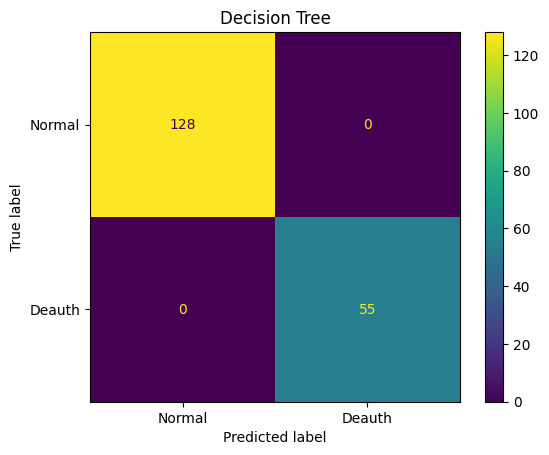

===== Random Forest
accuracy: 1.0
PR-AUC:   1.0
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       128
      Deauth       1.00      1.00      1.00        55

    accuracy                           1.00       183
   macro avg       1.00      1.00      1.00       183
weighted avg       1.00      1.00      1.00       183



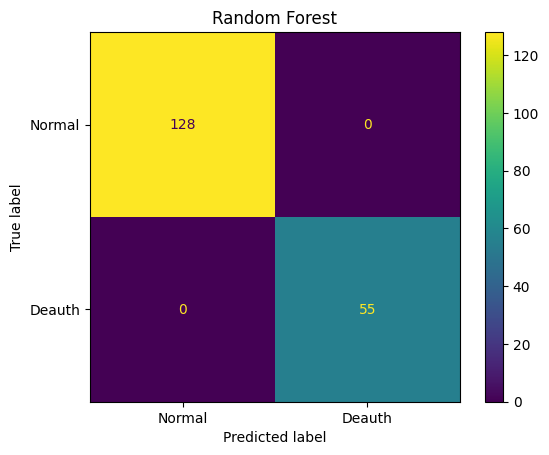

|--- n_deauth <= 24.00
|   |--- class: 0
|--- n_deauth >  24.00
|   |--- frac_deauth <= 0.34
|   |   |--- class: 1
|   |--- frac_deauth >  0.34
|   |   |--- class: 1



In [7]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, average_precision_score)
import matplotlib.pyplot as plt

dt = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                            random_state=0, n_jobs=-1).fit(Xtr, ytr)

for name, m in [("Decision Tree", dt), ("Random Forest", rf)]:
    pred = m.predict(Xte)
    print("=====", name)
    print("accuracy:", round(accuracy_score(yte, pred), 4))
    print("PR-AUC:  ", round(average_precision_score(yte, m.predict_proba(Xte)[:, 1]), 4))
    print(classification_report(yte, pred, target_names=["Normal", "Deauth"]))
    ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=["Normal", "Deauth"])
    plt.title(name); plt.show()

print(export_text(dt, feature_names=FEATS))

In [8]:
# Check 1: is there a gap between normal and attack deauth counts?
print("max n_deauth in Normal windows:", w.loc[w["label"] == 0, "n_deauth"].max())
print("min n_deauth in Deauth windows:", w.loc[w["label"] == 1, "n_deauth"].min())

# Check 2: can traffic volume alone separate the classes? (no deauth features)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

weak = ["n_frames", "n_mgmt"]
dt2 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0)
dt2.fit(Xtr[weak], ytr)
print(classification_report(yte, dt2.predict(Xte[weak]), target_names=["Normal", "Deauth"]))

max n_deauth in Normal windows: 0
min n_deauth in Deauth windows: 45
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       128
      Deauth       1.00      0.98      0.99        55

    accuracy                           0.99       183
   macro avg       1.00      0.99      0.99       183
weighted avg       0.99      0.99      0.99       183



### Findings: why the scores are perfect

- No Normal window contains a deauth frame (max 0), while every attack window contains at least 45. The classes are far apart, so a single threshold (about 24 deauth frames per second) separates them. A depth-3 tree is more than enough.
- Both models score 1.00 on the test set (183 windows, 55 of them attacks). The test set is small and easy, so this shows the attack is easy to see in a per-second count, not that the model is highly capable.
- Leakage check: with the deauth features removed, traffic volume alone still gives F1 of about 0.99. The Normal and attack windows come from different parts of the capture with different traffic levels, so volume acts as a proxy for the capture period.
- The deauth count is still a legitimate signal, but results should be read with this caveat. A harder test would use Normal windows from during the attack period.

## 7. Further Testing
The earlier split was made inside one set of windows, so the test windows sit close in time to the training windows. A stronger check is to train on some capture parts and test on others the model never saw.

- **Train:** `Deauth_5`, `_6`, `_7` (normal only) and `Deauth_21`, `_22`, `_24`, `_25`, `_26` (attacks).
- **Test:** `Deauth_8` (normal only) and `Deauth_23`, `_27`, `_28` (attacks).


In [9]:
def part_windows(fname):
    w_, _ = read_part(os.path.join(folder, fname))
    w_["frac_deauth"] = (w_["n_deauth"] / w_["n_mgmt"].replace(0, np.nan)).fillna(0)
    w_["label"] = (w_["n_attack"] > 0).astype(int)
    return w_

train_files = [f"Deauth_{i}.csv" for i in [5, 6, 7, 21, 22, 24, 25, 26]]   # 3 normal-only + 5 attack parts
test_files  = [f"Deauth_{i}.csv" for i in [8, 23, 27, 28]]                 # unseen: 1 normal-only + 3 attack parts

tr = pd.concat([part_windows(f) for f in train_files])
te = pd.concat([part_windows(f) for f in test_files])

dt3 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0)
dt3.fit(tr[FEATS], tr["label"])

pred = dt3.predict(te[FEATS])
print("train:", tr["label"].value_counts().to_dict())
print("test: ", te["label"].value_counts().to_dict())
print(classification_report(te["label"], pred, target_names=["Normal", "Deauth"], zero_division=0))

te = te.assign(pred=pred)
print(te.groupby("label")["pred"].agg(["size", "sum"]))     # windows, and how many were flagged

train: {1: 65, 0: 40}
test:  {1: 47, 0: 12}
              precision    recall  f1-score   support

      Normal       0.92      1.00      0.96        12
      Deauth       1.00      0.98      0.99        47

    accuracy                           0.98        59
   macro avg       0.96      0.99      0.97        59
weighted avg       0.98      0.98      0.98        59

       size  sum
label           
0        12    0
1        47   46


In [10]:
missed = te[(te["label"] == 1) & (te["pred"] == 0)]
print(missed[["sec", "n_frames", "n_mgmt", "n_deauth", "n_disas", "frac_deauth"]])

           sec  n_frames  n_mgmt  n_deauth  n_disas  frac_deauth
15  1608306693      2022       7         5        0     0.714286


### Findings
- 46 of 47 attack windows were detected, and none of the 12 normal windows was flagged. Deauth precision is 1.00 and recall is 0.98.
- Normal precision of 0.92 is the same single miss seen from the other side: one attack window was predicted as Normal.

### Limitation
- All parts come from the same capture session, so this shows consistency within the testbed. It does not show that the model generalises to other networks or to live traffic.

## Disassociation attack detection

Per-second windows are built from the `2.Disas` folder, one part at a time, and the earlier windows are used for training and the later ones for testing. This is done separately for Normal and attack windows, so both classes appear on both sides of the split.

In `Disas_33`, every `Disas` frame is subtype 10 (disassociation) and no normal frame shares that subtype, so the main feature is the number of disassociation frames per second. Normal disassociation frames did occur in other parts (22 in `Deauth_22`), so the whole folder is checked before concluding that this attack is easy to see.

In [11]:
import os, re
import numpy as np
import pandas as pd

root = '/kaggle/input/datasets/suumia/awid3-dataset/CSV'
folder_d = os.path.join(root, "2.Disas")

def part_no(f):
    return int(re.findall(r"\d+", f)[-1])

disas_parts = sorted(os.listdir(folder_d), key=part_no)
print(len(disas_parts), "parts")

41 parts


## 1. Build 1-second windows in batches

Each part is read on its own with only the columns needed, then reduced to one row per second. A second can span two parts, so the per-part summaries are added together by second. A window is labelled 1 (attack) if it contains any frame labelled `Disas`.

In [12]:
USE = ["frame.time_epoch", "wlan.fc.type", "wlan.fc.subtype", "Label"]

def windows_disas(files):
    out = []
    for f in files:                                    # one part at a time = batching
        c = pd.read_csv(os.path.join(folder_d, f), usecols=USE, low_memory=False)
        c["sec"] = np.floor(c["frame.time_epoch"].astype(float)).astype("int64")
        mg = c["wlan.fc.type"] == 0
        c["is_mgmt"]   = mg
        c["is_disas"]  = mg & (c["wlan.fc.subtype"] == 10)
        c["is_deauth"] = mg & (c["wlan.fc.subtype"] == 12)
        c["is_attack"] = c["Label"] != "Normal"
        out.append(c.groupby("sec").agg(
            n_frames=("sec", "size"), n_mgmt=("is_mgmt", "sum"),
            n_disas=("is_disas", "sum"), n_deauth=("is_deauth", "sum"),
            n_attack=("is_attack", "sum")).reset_index())
    w = pd.concat(out).groupby("sec", as_index=False).sum().sort_values("sec")
    w["frac_disas"] = (w["n_disas"] / w["n_mgmt"].replace(0, np.nan)).fillna(0)
    w["label"] = (w["n_attack"] > 0).astype(int)
    return w

Wd = windows_disas(disas_parts)
print(Wd.shape, Wd["label"].value_counts().to_dict())

(605, 8) {0: 423, 1: 182}


## 2. Normal vs. attack windows

How many disassociation frames per second occur in Normal and attack windows? If the ranges do not overlap, a simple threshold will separate them.

In [13]:
print(Wd.groupby("label")[["n_disas", "n_deauth", "n_frames"]].describe().T.round(1))

label                 0        1
n_disas  count    423.0    182.0
         mean       0.0    379.3
         std        0.0    495.1
         min        0.0      8.0
         25%        0.0    174.2
         50%        0.0    234.5
         75%        0.0    284.5
         max        1.0   2592.0
n_deauth count    423.0    182.0
         mean       0.0     33.7
         std        0.0     63.1
         min        0.0      0.0
         25%        0.0      0.0
         50%        0.0      0.0
         75%        0.0     34.8
         max        1.0    357.0
n_frames count    423.0    182.0
         mean    3315.3   3359.1
         std     3478.4   2981.8
         min       10.0    164.0
         25%       47.5   1038.2
         50%     1798.0   2170.5
         75%     6602.5   4932.2
         max    13322.0  11132.0
